In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "02_E0.8_rq2_tuong_quan_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 00:02:05 | INFO | Bắt đầu chạy 02_E0.8_rq2_tuong_quan_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0002_02_E0.8_rq2_tuong_quan_Han.log


# E0.8 – RQ2: tương quan giữa các biến và công suất

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.8 – RQ2: tương quan giữa các biến và công suất |
| **Mục đích** | Tách từ `02_eda.ipynb`: RQ2 (a), (b), (c) (mục 9, 10, 11). |
| **Đọc vào** | `data/processed/hourly_clean.csv` (do `01_cleaning` tạo) |
| **Ghi ra** | `data/eda_data/eda_rq2_*.csv`, `figures/eda_figures/02_rq2_scatter.*`, `figures/eda_figures/02_rq2_tuong_quan.*` |
| **Chạy sau** | `01_cleaning.ipynb` (cần `hourly_clean.csv`) |

Notebook EDA chỉ đọc và mô tả dữ liệu, không sửa, không xoá, không điền dữ liệu. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_Han.ipynb`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda_notebooks/
FILE = ROOT / "data" / "processed" / "hourly_clean.csv"
DIR_DATA = ROOT / "data" / "eda_data"
DIR_FIG = ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "svg.fonttype": "none"})

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
VAR_RQ2 = ["Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

DOW_LABEL = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
SEASON_ORDER = ["Xuân", "Hè", "Thu", "Đông"]
PERIOD_LABEL = {1: "Năm 1\n12/2006–11/2007", 2: "Năm 2\n12/2007–11/2008",
                3: "Năm 3\n12/2008–11/2009", 4: "Năm 4\n12/2009–11/2010"}

def season_of(m):
    """Mùa theo khí hậu Pháp (bắc bán cầu): Đông 12-2, Xuân 3-5, Hè 6-8, Thu 9-11."""
    if m in (12, 1, 2): return "Đông"
    if m in (3, 4, 5): return "Xuân"
    if m in (6, 7, 8): return "Hè"
    return "Thu"

def vn(x, d=3):
    """Số kiểu Việt Nam: dấu phẩy thập phân."""
    return f"{x:.{d}f}".replace(".", ",")

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def strength(r):
    a = abs(r)
    if a >= 0.7: return "mạnh"
    if a >= 0.4: return "trung bình"
    if a >= 0.2: return "yếu"
    return "rất yếu"

def save_fig(name):
    plt.savefig(DIR_FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.savefig(DIR_FIG / f"{name}.svg", bbox_inches="tight")

notes = []   # các câu gợi ý nhận xét (số liệu tự điền)
def add_note(tag, text):
    notes.append(f"- **[{tag}]** {text}")

In [3]:
raw = pd.read_csv(FILE, parse_dates=["datetime"], index_col="datetime")
assert (raw.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "Trục giờ không liên tục"

df = raw[COLS].copy()                       # chỉ 7 cột gốc, không dùng *_ffill
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek              # 0 = thứ 2 ... 6 = chủ nhật
df["is_weekend"] = df["dow"] >= 5
df["month"] = df.index.month
df["season"] = df["month"].map(season_of)
# Năm vận hành: tháng 12 đến tháng 11 năm sau (khớp với khoảng dữ liệu 12/2006 đến 11/2010)
df["period"] = np.asarray(((df.index.year * 12 + df.index.month) - (2006 * 12 + 12)) // 12 + 1)

n_all = len(df)
n_valid = int(df[TARGET].notna().sum())
print(f"Tổng số giờ: {fmt(n_all)} | Giờ có số đo thật: {fmt(n_valid)} | Giờ thiếu (bỏ qua): {fmt(n_all - n_valid)}")
print("Khoảng thời gian:", df.index[0], "->", df.index[-1])
print("Số giờ có số đo theo mùa:\n", df.groupby("season")[TARGET].count().reindex(SEASON_ORDER))
df.head()

Tổng số giờ: 34.588 | Giờ có số đo thật: 34.157 | Giờ thiếu (bỏ qua): 431
Khoảng thời gian: 2006-12-16 17:00:00 -> 2010-11-26 20:00:00
Số giờ có số đo theo mùa:
 season
Xuân    8736
Hè      8639
Thu     8549
Đông    8233
Name: Global_active_power, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,dow,is_weekend,month,season,period
datetime,,,,,,,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,17,5,True,12,Đông,1
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,18,5,True,12,Đông,1
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,19,5,True,12,Đông,1
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,20,5,True,12,Đông,1
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,21,5,True,12,Đông,1


In [4]:
MA_TN = "E0.8"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.8

## 9. RQ2 (a): Biểu đồ phân tán
Mỗi chấm là một giờ. Có hơn 30 nghìn điểm nên dùng biểu đồ hexbin (màu càng đậm càng nhiều điểm, thang log) thay cho scatter thường để khỏi chồng lấn. Ô thứ sáu (Global_reactive_power) là biến bổ sung, không thuộc danh sách của RQ2.

Số giờ dùng cho tương quan (đủ 7 cột): 34.157


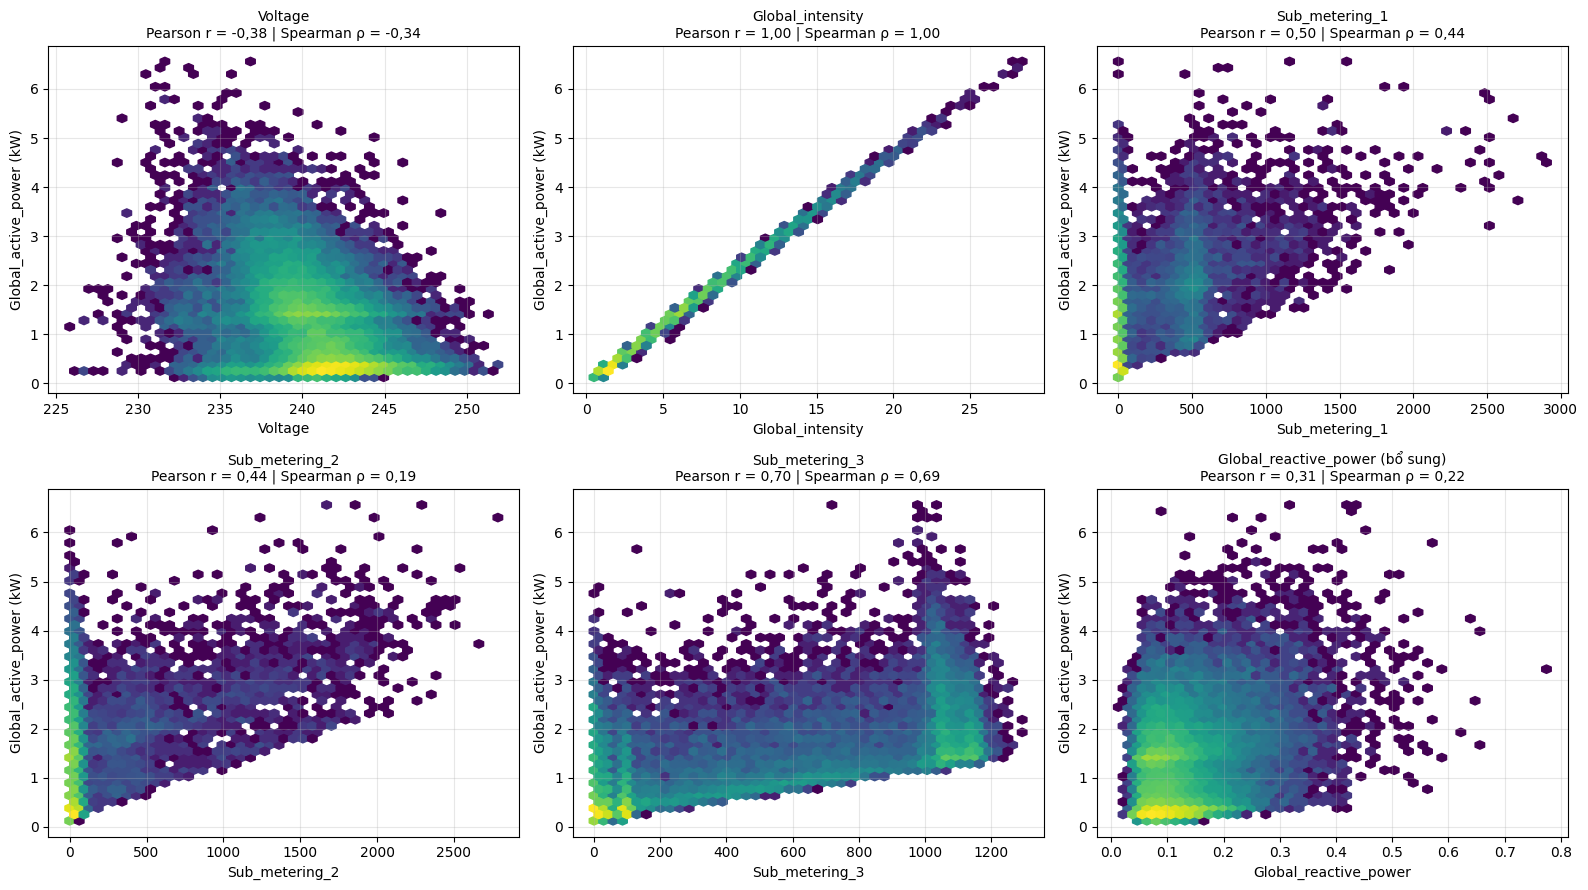

In [5]:
d2 = df[COLS].dropna()
print("Số giờ dùng cho tương quan (đủ 7 cột):", fmt(len(d2)))
pear = d2.corr(method="pearson")
spear = d2.corr(method="spearman")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), VAR_RQ2 + ["Global_reactive_power"]):
    hb = ax.hexbin(d2[c], d2[TARGET], gridsize=45, bins="log", mincnt=1, cmap="viridis")
    suffix = " (bổ sung)" if c == "Global_reactive_power" else ""
    ax.set_title(f"{c}{suffix}\nPearson r = {vn(pear.loc[c, TARGET], 2)} | Spearman ρ = {vn(spear.loc[c, TARGET], 2)}", fontsize=10)
    ax.set_xlabel(c); ax.set_ylabel("Global_active_power (kW)")
plt.tight_layout()
save_fig("02_rq2_scatter")
plt.show()

**Nhận xét:** Global_intensity nằm gần như trên một đường thẳng so với công suất (r = 0,999). Voltage có quan hệ nghịch yếu (r = −0,379). Sub_metering_3 có quan hệ dương trung bình (r = 0,696), còn Sub_metering_1 và 2 phân tán mạnh vì thiết bị chỉ bật trong thời gian ngắn.

## 10. RQ2 (b): Ma trận tương quan Pearson và Spearman
- **Pearson** đo quan hệ **tuyến tính**, nhạy với giá trị cực đoan.
- **Spearman** đo quan hệ **đơn điệu** (dựa trên thứ hạng), ít nhạy với ngoại lệ. Nếu hai hệ số chênh nhau nhiều thì quan hệ không tuyến tính hoặc chịu ảnh hưởng của giá trị cực đoan.
- Ngưỡng mô tả mức độ (quy ước chung): |r| ≥ 0,7 mạnh; 0,4 đến 0,7 trung bình; 0,2 đến 0,4 yếu; dưới 0,2 rất yếu.
- **Chỉ mô tả quan hệ, không suy diễn nhân quả.**

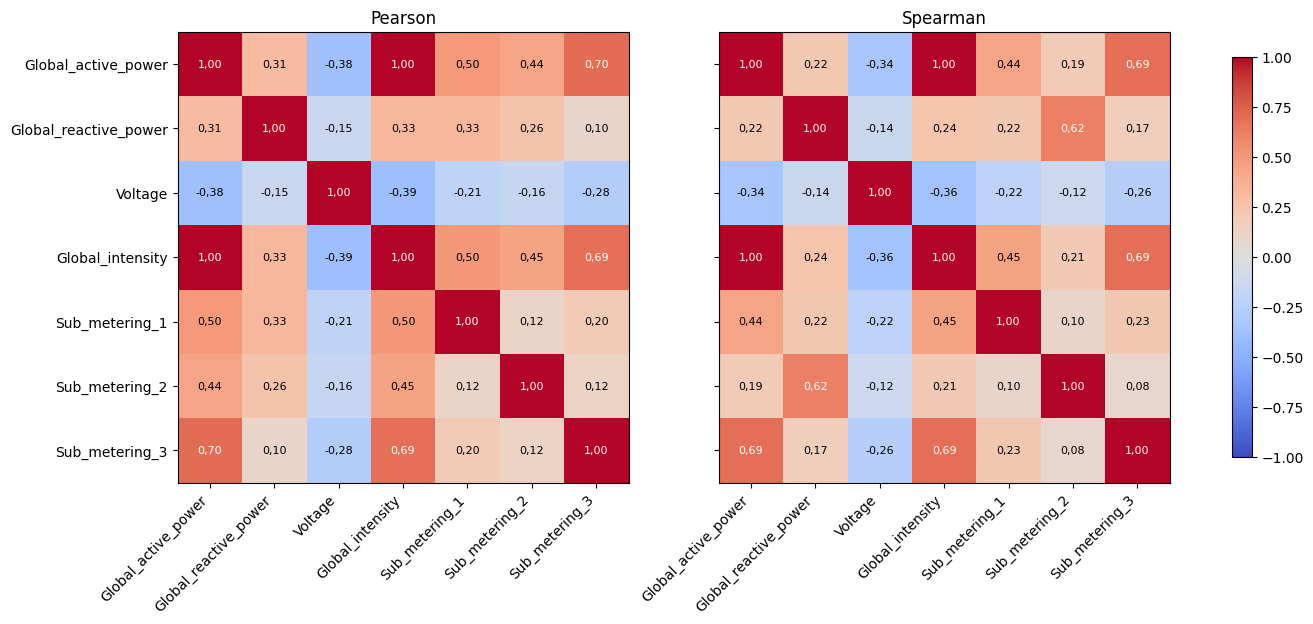

,Pearson,Spearman,Muc_do_Pearson,Muc_do_Spearman
Voltage,-0.379,-0.342,yếu,yếu
Global_intensity,0.999,0.998,mạnh,mạnh
Sub_metering_1,0.496,0.442,trung bình,trung bình
Sub_metering_2,0.440,0.188,trung bình,rất yếu
Sub_metering_3,0.696,0.694,trung bình,trung bình


In [6]:
def heat(ax, m, title, show_y=True):
    im = ax.imshow(m.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(m))); ax.set_yticks(range(len(m)))
    ax.set_xticklabels(m.columns, rotation=45, ha="right"); ax.set_yticklabels(m.index if show_y else [])
    for i in range(len(m)):
        for j in range(len(m)):
            ax.text(j, i, vn(m.values[i, j], 2), ha="center", va="center", fontsize=8,
                    color="white" if abs(m.values[i, j]) > 0.6 else "black")
    ax.set_title(title); ax.grid(False)
    return im

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
heat(ax[0], pear, "Pearson")
im = heat(ax[1], spear, "Spearman", show_y=False)
plt.colorbar(im, ax=list(ax), shrink=0.8)
save_fig("02_rq2_tuong_quan")
plt.show()

pear.round(4).to_csv(DIR_DATA / "eda_rq2_pearson.csv", index_label="bien")
spear.round(4).to_csv(DIR_DATA / "eda_rq2_spearman.csv", index_label="bien")

rq2 = pd.DataFrame({"Pearson": pear.loc[VAR_RQ2, TARGET], "Spearman": spear.loc[VAR_RQ2, TARGET]})
rq2["Muc_do_Pearson"] = rq2["Pearson"].map(strength)
rq2["Muc_do_Spearman"] = rq2["Spearman"].map(strength)
rq2.round(4).to_csv(DIR_DATA / "eda_rq2_voi_global_active_power.csv", index_label="bien")
rq2.round(3)

In [7]:
for c in VAR_RQ2:
    rp, rs = pear.loc[c, TARGET], spear.loc[c, TARGET]
    extra = " Hai hệ số chênh nhau trên 0,1: quan hệ có thể phi tuyến hoặc chịu ảnh hưởng của giá trị cực đoan." if abs(rp - rs) > 0.1 else ""
    add_note("RQ2", f"{c}: Pearson r = {vn(rp)} (mức {strength(rp)}); Spearman ρ = {vn(rs)} (mức {strength(rs)}).{extra}")

# Phần điện năng được ba công tơ phụ ghi nhận so với tổng điện năng cả hộ
e_total = (d2[TARGET] * 1000).sum()                  # kW trung bình mỗi giờ x 1000 = Wh mỗi giờ
share = {c: d2[c].sum() / e_total * 100 for c in SUB_COLS}
rest = 100 - sum(share.values())
add_note("RQ2-công tơ phụ", "Tỷ lệ điện năng ba công tơ phụ ghi nhận so với tổng điện năng cả hộ: " +
         "; ".join(f"{c} {vn(v, 1)}%" for c, v in share.items()) +
         f"; phần còn lại không qua công tơ phụ nào chiếm {vn(rest, 1)}%.")

**Nhận xét:** Global_intensity tương quan gần tuyệt đối với công suất (Pearson 0,999; Spearman 0,998) vì công suất bằng điện áp nhân cường độ, mà điện áp dao động rất ít; đây là quan hệ vật lý, không phải bằng chứng dự báo. Sub_metering_2 có Pearson 0,440 nhưng Spearman chỉ 0,188, chênh hơn 0,1, cho thấy quan hệ phi tuyến hoặc bị giá trị cực đoan chi phối. Voltage tương quan nghịch yếu (−0,379 và −0,342), phù hợp với việc lưới sụt áp khi nhiều thiết bị chạy cùng lúc. Tương quan không chứng minh quan hệ nhân quả.

## 11. RQ2 (c), bổ sung: Tương quan trễ (biến tại giờ t với công suất giờ t+1)
Đề tài **dự báo công suất của giờ t+1** và chỉ được dùng thông tin đến hết giờ t (Voltage, Global_intensity... của giờ t+1 là thông tin tương lai, không được đưa vào đầu vào). Vì vậy bảng này cho biết biến nào tại giờ t còn liên hệ với công suất giờ t+1. Đây là mô tả, không dùng để chọn mô hình.

In [8]:
tmp = df[COLS].copy()
tmp["GAP_t_cong_1"] = df[TARGET].shift(-1)      # công suất giờ t+1 (lưới giờ liên tục nên shift đúng nghĩa)
tmp = tmp.dropna()
lagged = pd.DataFrame({"Pearson": tmp.corr(method="pearson")["GAP_t_cong_1"].drop("GAP_t_cong_1"),
                       "Spearman": tmp.corr(method="spearman")["GAP_t_cong_1"].drop("GAP_t_cong_1")})
lagged.round(4).to_csv(DIR_DATA / "eda_rq2_tuong_quan_tre.csv", index_label="bien_tai_gio_t")
print("Số giờ dùng:", fmt(len(tmp)))
lagged.round(3)

Số giờ dùng: 34.144


,Pearson,Spearman
Global_active_power,0.713,0.756
Global_reactive_power,0.238,0.128
Voltage,-0.288,-0.272
Global_intensity,0.714,0.754
Sub_metering_1,0.297,0.319
Sub_metering_2,0.251,0.089
Sub_metering_3,0.455,0.474


In [9]:
order = lagged["Pearson"].abs().sort_values(ascending=False).index.tolist()
add_note("RQ2-tương quan trễ", "Tương quan Pearson giữa công suất giờ t+1 và biến tại giờ t, xếp từ cao xuống thấp: " +
         "; ".join(f"{c} {vn(lagged.loc[c, 'Pearson'])}" for c in order) + ".")
add_note("RQ2-so sánh", f"So sánh với tương quan cùng giờ: Global_intensity cùng giờ có r = {vn(pear.loc['Global_intensity', TARGET])}, "
         f"còn Global_intensity giờ t với công suất giờ t+1 có r = {vn(lagged.loc['Global_intensity', 'Pearson'])}.")

**Nhận xét:** Khi dự báo giờ t+1, tương quan với biến tại giờ t giảm rõ: Global_intensity chỉ còn 0,714 (so với 0,999 cùng giờ), ngang với chính công suất giờ t (0,713); tiếp theo là Sub_metering_3 (0,455), Sub_metering_1 (0,297), Voltage (−0,288), Sub_metering_2 (0,251), Global_reactive_power (0,238). Không biến nào còn trùng với nhãn, nên dùng các biến đo tại giờ t làm đặc trưng không gây rò rỉ dữ liệu.

## Gợi ý nhận xét E0.8 (số tự điền)

In [10]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 00:02:08 | INFO | Gợi ý nhận xét E0.8 (số tự điền), lưu ở data/eda_E0.8_goi_y_nhan_xet.md:
- **[RQ2]** Voltage: Pearson r = -0,379 (mức yếu); Spearman ρ = -0,342 (mức yếu).
- **[RQ2]** Global_intensity: Pearson r = 0,999 (mức mạnh); Spearman ρ = 0,998 (mức mạnh).
- **[RQ2]** Sub_metering_1: Pearson r = 0,496 (mức trung bình); Spearman ρ = 0,442 (mức trung bình).
- **[RQ2]** Sub_metering_2: Pearson r = 0,440 (mức trung bình); Spearman ρ = 0,188 (mức rất yếu). Hai hệ số chênh nhau trên 0,1: quan hệ có thể phi tuyến hoặc chịu ảnh hưởng của giá trị cực đoan.
- **[RQ2]** Sub_metering_3: Pearson r = 0,696 (mức trung bình); Spearman ρ = 0,694 (mức trung bình).
- **[RQ2-công tơ phụ]** Tỷ lệ điện năng ba công tơ phụ ghi nhận so với tổng điện năng cả hộ: Sub_metering_1 6,2%; Sub_metering_2 7,1%; Sub_metering_3 35,5%; phần còn lại không qua công tơ phụ nào chiếm 51,2%.
- **[RQ2-tương quan trễ]** Tương quan Pearson giữa công suất giờ t+1 và biến tại giờ t, xếp từ cao xuống thấp: Global_

## Log lên W&B (minh chứng)

In [11]:
# W&B (project cuoi-ky-du-bao-dien-nang). Mặc định TẮT để chạy lại không tạo run trùng.
# Muốn ghi lên W&B: chạy notebook bằng lệnh  BAT_WANDB=1 jupyter nbconvert --to notebook --execute --inplace <notebook>
import os
USE_WANDB = os.environ.get("BAT_WANDB") == "1"
if USE_WANDB:
    import wandb, pandas as pd
    BANG = ['eda_rq2_voi_global_active_power.csv', 'eda_rq2_pearson.csv', 'eda_rq2_spearman.csv', 'eda_rq2_tuong_quan_tre.csv']
    HINH = ['02_rq2_scatter.png', '02_rq2_tuong_quan.png']
    run = wandb.init(entity="sgu-mayhoc-nhom11", project="cuoi-ky-du-bao-dien-nang",
                     name="ck-E0.8-Han-rq2-tuong-quan", tags=["E0.8", "Han", "EDA"],
                     config={"notebook": TEN_NOTEBOOK, "file_log": str(file_log)})
    run.summary.update({})
    run.log({**{"bang/" + b.removesuffix(".csv"): wandb.Table(dataframe=pd.read_csv(DIR_DATA / b)) for b in BANG},
             **{"hinh/" + h.removesuffix(".png"): wandb.Image(str(DIR_FIG / h)) for h in HINH},
             "ket_luan": wandb.Html("<br>".join(str(x) for x in notes[moc_note:]))})
    log.info(f"Đã ghi W&B: {run.url}")
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/caongochan/.netrc.


wandb: Currently logged in as: caongochan142 (sgu-mayhoc-nhom11) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run wf0aa4e0


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/notebooks/eda/wandb/run-20261114_000209-wf0aa4e0
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run ck-E0.8-Han-rq2-tuong-quan


... (8 outputs left out)

wandb: uploading artifact run-wf0aa4e0-bangeda_rq2_tuong_quan_tre-hUaubg; uploading media/images/hinh/02_rq2_scatter_0_fd0ffac457c8cc563010.png


wandb: uploading history steps 0-0, summary, console lines 0-0


wandb: 🚀 View run ck-E0.8-Han-rq2-tuong-quan at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang/runs/wf0aa4e0
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang
wandb: Synced 5 W&B file(s), 7 media file(s), 8 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_000209-wf0aa4e0/logs


## Nhật ký

- 01/11/2026 – Viết lần đầu trong notebook `02_eda.ipynb`. Commit `74a9949`.
- 07/11/2026 – Sửa `02_eda.ipynb`. Commit `9a1f293`, `910a450`.
- 13/11/2026 – Tách RQ2 (a), (b), (c) (mục 9, 10, 11) ra khỏi `02_eda.ipynb` thành notebook riêng `02_E0.8_rq2_tuong_quan_Han.ipynb`, thêm ô ghi log. Commit `cdf1bfd` (lúc này notebook chưa chạy).
- 13/11/2026 – Chạy lúc 19:59, commit log và bảng kết quả. Commit `93e7086`, lưu notebook có output ở commit `8073a1d`.
- 13/11/2026 – Chạy lại lúc 20:16 bằng `jupyter nbconvert` cho đủ output tất cả các ô; nội dung log trùng với lần 19:59. Commit `01d5f29`.
- 13/11/2026 – Chuyển các file log EDA vào `logs/eda_log/` và sửa ô ghi log để các lần chạy sau ghi thẳng vào thư mục này. Commit `44b69dd`.